<a href="https://colab.research.google.com/github/Al-32byte/wignerweisskopfpinn/blob/main/wignerWispinn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Using device: cuda
Predicted Einstein A coefficient (Fermi Golden Rule): 0.113883

Training...
epoch 0, loss 88.089310
epoch 200, loss 0.017488
epoch 400, loss 0.014795
epoch 600, loss 0.007369
epoch 800, loss 0.007443

Einstein A coefficient — analytic (Fermi's Golden Rule): 0.113883
Einstein A coefficient — extracted from trained PINN:    0.249886
Relative error: 119.42%


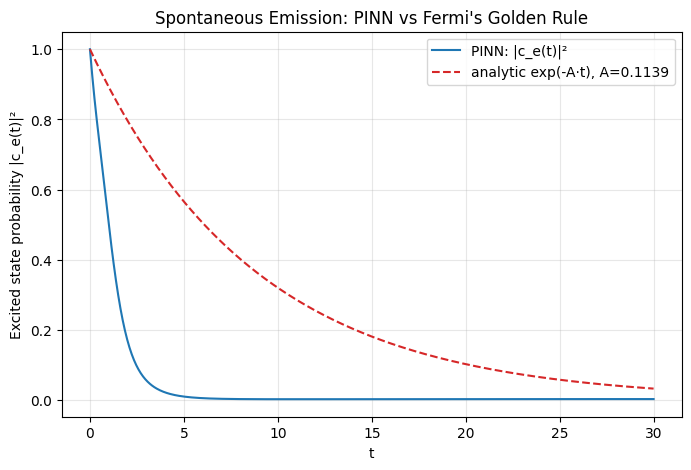

In [ ]:


import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(0)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


omega_a = 1.0
N_modes = 30
bandwidth = 4.0
g0 = 0.05

omega_k = np.linspace(omega_a - bandwidth/2, omega_a + bandwidth/2, N_modes)
delta_omega = omega_k[1] - omega_k[0]
g_k = np.full(N_modes, g0)

A_predicted = 2 * np.pi * g0**2 / delta_omega
print(f"Predicted Einstein A coefficient (Fermi Golden Rule): {A_predicted:.6f}")

omega_k_t = torch.tensor(omega_k, dtype=torch.float32, device=device)
g_k_t = torch.tensor(g_k, dtype=torch.float32, device=device)


class WignerWeisskopfPINN(nn.Module):
    def __init__(self, n_modes, hidden=128):
        super().__init__()
        out_dim = 2 * (1 + n_modes)
        self.net = nn.Sequential(
            nn.Linear(1, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh(),
            nn.Linear(hidden, out_dim)
        )
        self.n_modes = n_modes

    def forward(self, t):
        out = self.net(t)
        ce_re = out[:, 0:1]
        ce_im = out[:, 1:2]
        ck_re = out[:, 2:2+self.n_modes]
        ck_im = out[:, 2+self.n_modes:2+2*self.n_modes]
        return ce_re, ce_im, ck_re, ck_im

model = WignerWeisskopfPINN(N_modes).to(device)


def compute_derivatives(model, t):
    t.requires_grad_(True)
    ce_re, ce_im, ck_re, ck_im = model(t)


    dce_re = torch.autograd.grad(ce_re, t, grad_outputs=torch.ones_like(ce_re),
                                  create_graph=True)[0]
    dce_im = torch.autograd.grad(ce_im, t, grad_outputs=torch.ones_like(ce_im),
                                  create_graph=True)[0]


    dck_re = torch.cat([
        torch.autograd.grad(ck_re[:, i:i+1], t, grad_outputs=torch.ones_like(ck_re[:, i:i+1]),
                             create_graph=True)[0]
        for i in range(ck_re.shape[1])
    ], dim=1)
    dck_im = torch.cat([
        torch.autograd.grad(ck_im[:, i:i+1], t, grad_outputs=torch.ones_like(ck_im[:, i:i+1]),
                             create_graph=True)[0]
        for i in range(ck_im.shape[1])
    ], dim=1)

    return ce_re, ce_im, ck_re, ck_im, dce_re, dce_im, dck_re, dck_im


def loss_fn(model, t_colloc, t0):
    (ce_re, ce_im, ck_re, ck_im,
     dce_re, dce_im, dck_re, dck_im) = compute_derivatives(model, t_colloc)

    coupling_re = torch.sum(g_k_t.unsqueeze(0) * ck_re, dim=1, keepdim=True)
    coupling_im = torch.sum(g_k_t.unsqueeze(0) * ck_im, dim=1, keepdim=True)

    res_e_re = -dce_im - (omega_a * ce_re + coupling_re)
    res_e_im =  dce_re - (omega_a * ce_im + coupling_im)

    res_k_re = -dck_im - (omega_k_t.unsqueeze(0) * ck_re + g_k_t.unsqueeze(0) * ce_re)
    res_k_im =  dck_re - (omega_k_t.unsqueeze(0) * ck_im + g_k_t.unsqueeze(0) * ce_im)

    loss_pde = (res_e_re**2).mean() + (res_e_im**2).mean() \
             + (res_k_re**2).mean() + (res_k_im**2).mean()

    ce_re0, ce_im0, ck_re0, ck_im0 = model(t0)
    loss_ic = (ce_re0 - 1.0)**2 + (ce_im0)**2 \
            + (ck_re0**2).mean() + (ck_im0**2).mean()

    return loss_pde + 100 * loss_ic.mean()


optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
T_max = 30.0
t0 = torch.zeros(1, 1, device=device)

n_epochs = 1000

print("\nTraining...")
for epoch in range(n_epochs):
    t_colloc = (torch.rand(256, 1) * T_max).to(device)

    optimizer.zero_grad()
    loss = loss_fn(model, t_colloc, t0)
    loss.backward()
    optimizer.step()

    if epoch % 200 == 0:
        print(f"epoch {epoch}, loss {loss.item():.6f}")


with torch.no_grad():
    t_eval = torch.linspace(0, T_max, 500).reshape(-1, 1).to(device)
    ce_re, ce_im, _, _ = model(t_eval)
    prob_excited = (ce_re**2 + ce_im**2).cpu().numpy().flatten()
    t_np = t_eval.cpu().numpy().flatten()

fit_mask = (t_np > 0.5) & (t_np < T_max * 0.6) & (prob_excited > 1e-6)
slope, intercept = np.polyfit(t_np[fit_mask], np.log(prob_excited[fit_mask]), 1)
A_extracted = -slope

print(f"\nEinstein A coefficient — analytic (Fermi's Golden Rule): {A_predicted:.6f}")
print(f"Einstein A coefficient — extracted from trained PINN:    {A_extracted:.6f}")
print(f"Relative error: {abs(A_extracted - A_predicted)/A_predicted * 100:.2f}%")

plt.figure(figsize=(8, 5))
plt.plot(t_np, prob_excited, label="PINN: |c_e(t)|²", color="tab:blue")
plt.plot(t_np, np.exp(-A_predicted * t_np), "--", color="tab:red",
          label=f"analytic exp(-A·t), A={A_predicted:.4f}")
plt.xlabel("t")
plt.ylabel("Excited state probability |c_e(t)|²")
plt.title("Spontaneous Emission: PINN vs Fermi's Golden Rule")
plt.legend()
plt.grid(alpha=0.3)
plt.show()